# Remake -- does external data help? (RQ1)

Same data, features, folds and per-fold processing as `remake_train.ipynb`
(sections 1--4 copied unchanged). Answers RQ1 for the remake pipeline:

1. **Baseline vs augmented.** The same XGBoost model (fixed settings) is
   trained twice on the same 5 time-ordered folds: once on the property's
   own features only, once on all 27 features.
2. **Paired bootstrap** -- is the improvement real or luck?
3. **Two-stage residual test** -- do the external features carry *new*
   information, or only repeat what the property features already say?
4. **Which external features matter** -- grouped permutation importance,
   SHAP and drop-one / drop-group retraining, on fold 5.

Run time: about 1--2 minutes.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/remake_dataset.parquet")

# TimeSeriesSplit assumes row order IS time order -- sort explicitly rather
# than relying on the order the parquet was written in.
df = df.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Date range: {df['sale_date_parsed'].min().date()} to {df['sale_date_parsed'].max().date()}")

Loaded 59,708 rows, 33 columns
Date range: 2024-01-01 to 2026-08-18


## 1. Feature groups

In [2]:
ID_COLS = ["valuation_id_concat", "sale_id", "sale_date_parsed"]
TARGET = "sale_price_gross"

CAT_COLS = [
    "property_type", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "noise_category_combination",
]
BOOL_COLS = ["in_flood_plain"]
NUM_COLS = [
    # property
    "land_area", "building_total_floor_area",
    "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
    # location / spatial
    "latitude", "longitude", "distance_to_cbd", "walk_supermarket_network_m",
    "walk_bus_stop_network_m", "distance_to_school", "area_level_deprivation_index",
    # socioeconomic
    "median_personal_income_by_sa", "employment_rate_by_sa", "unemployment_rate_by_sa",
    "population_counts_by_sa", "population_density",
    # environment
    "distance_to_coastline",
    # market / time
    "building_consents", "sale_year", "sale_month",
]
FEATURE_COLS = CAT_COLS + BOOL_COLS + NUM_COLS

# Near-duplicates dropped after remake_feature_reduction.ipynb (set C):
# sale_quarter is calculated from sale_month, and mass_total_floor_area repeats
# building_total_floor_area (rho 0.96). Dropping both cost under 0.5% RMSE.
DROPPED_COLS = ["sale_quarter", "mass_total_floor_area"]

unassigned = set(df.columns) - set(FEATURE_COLS) - set(ID_COLS) - {TARGET} - set(DROPPED_COLS)
missing = set(FEATURE_COLS) - set(df.columns)
assert not unassigned, f"Columns not assigned to any group: {unassigned}"
assert not missing, f"Feature columns not in dataset: {missing}"

print(f"{len(FEATURE_COLS)} features: {len(CAT_COLS)} categorical, {len(BOOL_COLS)} boolean, {len(NUM_COLS)} numeric")

27 features: 5 categorical, 1 boolean, 21 numeric


### 1.1 Property-only (baseline) vs external features

**Baseline** = what the council sales file says about the property itself,
plus the sale date. **External** = everything added from outside data
(coordinates, distances, SA2 census and deprivation, hazards, consents).

In [3]:
PROPERTY_COLS = [
    "property_type", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator",
    "land_area", "building_total_floor_area",
    "off_street_parking", "mass_garage_under_main_roof", "mass_garage_freestanding",
    "sale_year", "sale_month",
]
EXTERNAL_COLS = [c for c in FEATURE_COLS if c not in PROPERTY_COLS]

# Same themes as the house explanations in remake_train.ipynb section 7.3.
EXTERNAL_GROUPS = {
    "Location": ["latitude", "longitude", "distance_to_cbd", "distance_to_coastline",
                 "distance_to_school", "walk_supermarket_network_m", "walk_bus_stop_network_m"],
    "Neighbourhood": ["area_level_deprivation_index", "median_personal_income_by_sa",
                      "employment_rate_by_sa", "unemployment_rate_by_sa",
                      "population_counts_by_sa", "population_density"],
    "Hazards": ["in_flood_plain", "noise_category_combination"],
    "Development": ["building_consents"],
}
assert sorted(sum(EXTERNAL_GROUPS.values(), [])) == sorted(EXTERNAL_COLS)
assert set(PROPERTY_COLS) <= set(FEATURE_COLS)
print(f"Baseline: {len(PROPERTY_COLS)} features | external: {len(EXTERNAL_COLS)} | augmented: {len(FEATURE_COLS)}")

Baseline: 11 features | external: 16 | augmented: 27


## 2. Per-fold processing (same as `remake_train.ipynb` section 3)

In [4]:
def prepare_fold(train_df, test_df):
    """Encode, impute and price-trim one fold. Returns X/y for train and test."""
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[CAT_COLS])

    X_train = train_df[FEATURE_COLS].copy()
    X_test = test_df[FEATURE_COLS].copy()
    X_train[CAT_COLS] = encoder.transform(train_df[CAT_COLS])
    X_test[CAT_COLS] = encoder.transform(test_df[CAT_COLS])
    for col in BOOL_COLS:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    nan_cols = [c for c in NUM_COLS if X_train[c].isna().any() or X_test[c].isna().any()]
    train_medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(train_medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(train_medians)

    y_train = train_df[TARGET].values
    y_test = test_df[TARGET].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    return {
        "X_train": X_train[train_keep], "y_train": y_train[train_keep],
        "X_test": X_test[test_keep], "y_test": y_test[test_keep],
        "test_idx": test_df.index[test_keep], "price_limits": (p1, p99),
    }

## 3. Build the 5 folds

In [5]:
kf = TimeSeriesSplit(n_splits=5)
folds = []
rows = []
for fold_i, (train_idx, test_idx) in enumerate(kf.split(df), start=1):
    f = prepare_fold(df.iloc[train_idx], df.iloc[test_idx])
    assert not f["X_train"].isna().any().any() and not f["X_test"].isna().any().any()
    folds.append(f)
    rows.append({
        "fold": fold_i,
        "train_period_end": df.iloc[train_idx]["sale_date_parsed"].max().date(),
        "test_period": f"{df.iloc[test_idx]['sale_date_parsed'].min().date()} to {df.iloc[test_idx]['sale_date_parsed'].max().date()}",
        "n_train": len(f["y_train"]), "n_test": len(f["y_test"]),
        "price_p1": f["price_limits"][0], "price_p99": f["price_limits"][1],
    })

fold_summary = pd.DataFrame(rows).set_index("fold")
print(f"Total test rows across folds: {fold_summary['n_test'].sum():,}")
fold_summary

Total test rows across folds: 48,777


,train_period_end,test_period,n_train,n_test,price_p1,price_p99
fold,,,,,,
1,2024-06-19,2024-06-19 to 2024-11-07,9760,9779,450000.0,4512000.0
2,2024-11-07,2024-11-07 to 2025-04-01,19505,9685,450000.0,4229700.0
3,2025-04-01,2025-04-01 to 2025-08-22,29263,9783,430000.0,4261500.0
4,2025-08-22,2025-08-22 to 2026-01-24,39008,9761,433089.1,4219250.0
5,2026-01-24,2026-01-24 to 2026-08-18,48774,9769,430243.6,4200000.0


## 4. Baseline vs augmented (H1)

Same XGBoost settings as everywhere else in the project (500 trees, depth 6,
learning rate 0.05, 80% row and column sampling, seed 42). Both models see
exactly the same sales; the only difference is the feature list.

In [6]:
import time
from xgboost import XGBRegressor


def make_xgb():
    return XGBRegressor(
        n_estimators=500, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
    )


def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))


def mae(y, yhat):
    return np.mean(np.abs(y - yhat))


def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100


SETS = {"Baseline": PROPERTY_COLS, "Augmented": FEATURE_COLS}

oof = pd.DataFrame(
    {
        "actual": np.concatenate([f["y_test"] for f in folds]),
        "fold": np.concatenate([np.full(len(f["y_test"]), i) for i, f in enumerate(folds, start=1)]),
    },
    index=np.concatenate([f["test_idx"] for f in folds]),
)
fold_rows = []
for name, cols in SETS.items():
    start = time.time()
    preds = []
    for fold_i, f in enumerate(folds, start=1):
        model = make_xgb().fit(f["X_train"][cols], f["y_train"])
        pred = model.predict(f["X_test"][cols])
        preds.append(pred)
        fold_rows.append({"set": name, "fold": fold_i, "RMSE": rmse(f["y_test"], pred), "MAPE": mape(f["y_test"], pred)})
    oof[name] = np.concatenate(preds)
    print(f"{name} ({len(cols)} features): 5 folds in {time.time() - start:.0f}s")

ablation = pd.DataFrame([
    {"set": name, "features": len(cols),
     "RMSE": rmse(oof["actual"], oof[name]), "MAE": mae(oof["actual"], oof[name]),
     "MAPE": mape(oof["actual"], oof[name])}
    for name, cols in SETS.items()
]).set_index("set")
print(f"Pooled over {len(oof):,} test predictions")
ablation.round(2)

Baseline (11 features): 5 folds in 2s


Augmented (27 features): 5 folds in 4s
Pooled over 48,777 test predictions


,features,RMSE,MAE,MAPE
set,,,,
Baseline,11,343717.99,223224.41,19.34
Augmented,27,212677.77,127982.72,10.98


In [7]:
print("RMSE by fold:")
pd.DataFrame(fold_rows).pivot(index="fold", columns="set", values="RMSE").round(0)

RMSE by fold:


set,Augmented,Baseline
fold,,
1,238373.0,370069.0
2,219868.0,346986.0
3,207194.0,346446.0
4,203509.0,332226.0
5,191483.0,320862.0


### 4.1 Paired bootstrap

Draw the test sales with replacement 2,000 times and score **both** models
on each resample, so the comparison stays paired. The 2.5th--97.5th
percentiles of `baseline - augmented` give a 95% confidence interval; if it
excludes zero the improvement is not luck.

In [8]:
B = 2000
rng = np.random.default_rng(42)
y = oof["actual"].values
err = {name: oof[name].values - y for name in SETS}
diffs = {"RMSE": [], "MAE": [], "MAPE": []}
for _ in range(B):
    s = rng.integers(0, len(y), len(y))
    eb, ea, ys = err["Baseline"][s], err["Augmented"][s], y[s]
    diffs["RMSE"].append(np.sqrt(np.mean(eb ** 2)) - np.sqrt(np.mean(ea ** 2)))
    diffs["MAE"].append(np.mean(np.abs(eb)) - np.mean(np.abs(ea)))
    diffs["MAPE"].append((np.mean(np.abs(eb / ys)) - np.mean(np.abs(ea / ys))) * 100)

bootstrap = pd.DataFrame({
    m: {"improvement": ablation.loc["Baseline", m] - ablation.loc["Augmented", m],
        "CI 2.5%": np.percentile(d, 2.5), "CI 97.5%": np.percentile(d, 97.5)}
    for m, d in diffs.items()
}).T
bootstrap["excludes zero"] = (bootstrap["CI 2.5%"] > 0) | (bootstrap["CI 97.5%"] < 0)
bootstrap.round(2)

,improvement,CI 2.5%,CI 97.5%,excludes zero
RMSE,131040.22,126988.49,135157.23,True
MAE,95241.68,93358.23,97194.16,True
MAPE,8.36,8.20,8.51,True


### 4.2 Figure for the report

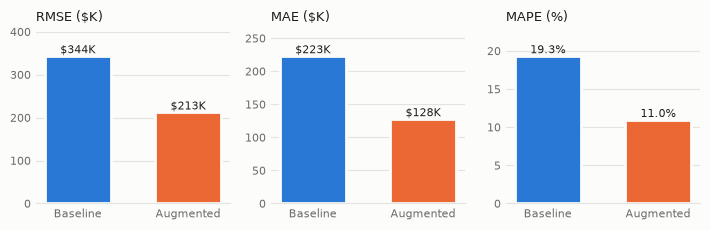

In [9]:
import matplotlib.pyplot as plt

SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#1f1f1e", "#6b6b68", "#e4e3df"
SET_COLORS = {"Baseline": "#2a78d6", "Augmented": "#eb6834"}  # categorical slots 1 and 2
PANELS = [("RMSE", 1000, "RMSE ($K)", "${:,.0f}K"), ("MAE", 1000, "MAE ($K)", "${:,.0f}K"),
          ("MAPE", 1, "MAPE (%)", "{:.1f}%")]

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.4), facecolor=SURFACE)
for ax, (metric, scale, title, fmt) in zip(axes, PANELS):
    ax.set_facecolor(SURFACE)
    values = ablation[metric] / scale
    bars = ax.bar(values.index, values.values, width=0.6,
                  color=[SET_COLORS[s] for s in values.index], edgecolor=SURFACE, linewidth=2)
    for bar, v in zip(bars, values.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v, fmt.format(v).replace("$", "\\$"),
                ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_title(title, fontsize=9, color=INK, loc="left")
    ax.set_ylim(0, values.max() * 1.18)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, labelsize=8, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
plt.tight_layout()
plt.savefig("figures/baseline_vs_augmented_metrics.png", dpi=300, bbox_inches="tight", facecolor=SURFACE)
plt.show()

## 5. Two-stage residual test (H2)

**Stage 1:** the baseline model's out-of-fold error for each sale,
`r = actual - baseline prediction`.
**Stage 2:** a new XGBoost model that sees **only the 16 external features**
predicts `r`, using its own 5-fold time-ordered split over those sales (the
first block is training only). Stage 2 never sees a property feature, so an
out-of-fold R² above zero means the external features explain something the
property features missed.

In [10]:
from sklearn.metrics import r2_score

# oof rows are in date order already (folds are consecutive time blocks).
assert df.loc[oof.index, "sale_date_parsed"].is_monotonic_increasing
X_ext = pd.concat([f["X_test"][EXTERNAL_COLS] for f in folds]).loc[oof.index]
resid = (oof["actual"] - oof["Baseline"]).values

stage2_pred = np.full(len(resid), np.nan)
for train_i, test_i in TimeSeriesSplit(n_splits=5).split(X_ext):
    m2 = make_xgb().fit(X_ext.iloc[train_i], resid[train_i])
    stage2_pred[test_i] = m2.predict(X_ext.iloc[test_i])

has = ~np.isnan(stage2_pred)
two_stage = pd.Series({
    "sales with a stage-2 prediction": has.sum(),
    "stage-2 out-of-fold R2": r2_score(resid[has], stage2_pred[has]),
    "residual RMSE before ($)": np.sqrt(np.mean(resid[has] ** 2)),
    "residual RMSE after ($)": np.sqrt(np.mean((resid[has] - stage2_pred[has]) ** 2)),
})
two_stage.round(3)

sales with a stage-2 prediction     40645.000
stage-2 out-of-fold R2                  0.293
residual RMSE before ($)           339582.032
residual RMSE after ($)            285308.484
dtype: float64

## 6. Which external features matter?

All on **fold 5** (train up to January 2026, test January -- August 2026),
the same split as the SHAP and house-explanation sections of
`remake_train.ipynb`. Three methods, because each one can mislead on its own
when features overlap:

- **Grouped permutation importance:** shuffle a group of features together in
  the test set (rows moved as a block) and measure the RMSE increase; 20
  repeats.
- **SHAP:** `TreeExplainer` on the same 500 test sales as `remake_train.ipynb`.
- **Drop-one / drop-group retraining:** retrain without a feature (or group)
  and measure the change in test RMSE. A similar feature can stand in for a
  dropped one, so this tends to *understate* importance; permutation tends to
  overstate it; SHAP splits credit between similar features.

In [11]:
import shap

f5 = folds[-1]
full5 = make_xgb().fit(f5["X_train"], f5["y_train"])
rmse5 = rmse(f5["y_test"], full5.predict(f5["X_test"]))
print(f"Fold 5 augmented model: {len(f5['y_test']):,} test sales, RMSE ${rmse5:,.0f}")


def permuted_rmse(cols, repeats=20, seed=42):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(repeats):
        X = f5["X_test"].copy()
        X[cols] = X[cols].values[rng.permutation(len(X))]
        out.append(rmse(f5["y_test"], full5.predict(X)))
    return np.mean(out)


def drop_rmse(cols):
    keep = [c for c in FEATURE_COLS if c not in cols]
    m = make_xgb().fit(f5["X_train"][keep], f5["y_train"])
    return rmse(f5["y_test"], m.predict(f5["X_test"][keep]))


shap_sample = f5["X_test"].sample(n=500, random_state=42)
sv = shap.TreeExplainer(full5).shap_values(shap_sample)
shap_mean = pd.Series(np.abs(sv).mean(axis=0), index=FEATURE_COLS)
shap_pct = shap_mean / shap_mean.sum() * 100

start = time.time()
group_rows = []
for group, cols in {"All external": EXTERNAL_COLS, **EXTERNAL_GROUPS}.items():
    group_rows.append({
        "group": group, "features": len(cols),
        "permutation dRMSE %": (permuted_rmse(cols) / rmse5 - 1) * 100,
        "SHAP share %": shap_pct[cols].sum(),
        "drop-group dRMSE ($)": drop_rmse(cols) - rmse5,
    })
print(f"Groups done in {time.time() - start:.0f}s")
group_table = pd.DataFrame(group_rows).set_index("group")
print(f"Property features' SHAP share: {shap_pct[PROPERTY_COLS].sum():.1f}%")
group_table.round(1)

D:\Codes\COMPSCI_760_Group_3_Intelligent_Real_Estate_Price_Prediction_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fold 5 augmented model: 9,769 test sales, RMSE $191,483


Groups done in 5s
Property features' SHAP share: 47.7%


,features,permutation dRMSE %,SHAP share %,drop-group dRMSE ($)
group,,,,
All external,16,171.2,52.299999,129379.0
Location,7,131.1,35.099998,20145.6
Neighbourhood,6,32.1,16.100000,1665.1
Hazards,2,0.3,0.400000,370.1
Development,1,0.6,0.600000,-1488.6


In [12]:
start = time.time()
feature_table = pd.DataFrame({
    "SHAP share %": shap_pct[EXTERNAL_COLS],
    "drop-one dRMSE ($)": pd.Series({c: drop_rmse([c]) - rmse5 for c in EXTERNAL_COLS}),
}).sort_values("SHAP share %", ascending=False)
print(f"Drop-one done in {time.time() - start:.0f}s (negative = slightly better without it)")
feature_table.round(1)

Drop-one done in 14s (negative = slightly better without it)


,SHAP share %,drop-one dRMSE ($)
distance_to_cbd,15.5,1668.4
longitude,8.6,3174.4
latitude,8.1,3751.9
area_level_deprivation_index,6.9,-821.0
median_personal_income_by_sa,3.4,562.8
employment_rate_by_sa,3.2,-956.3
unemployment_rate_by_sa,1.2,-61.7
distance_to_coastline,1.1,1763.3
population_density,0.9,-579.0
walk_supermarket_network_m,0.9,354.8


<>:3: SyntaxWarning: invalid escape sequence '\$'
<>:3: SyntaxWarning: invalid escape sequence '\$'
C:\Users\AD\AppData\Local\Temp\ipykernel_3228\2599435225.py:3: SyntaxWarning: invalid escape sequence '\$'
  plt.xlabel("SHAP value (\$ thousands)")


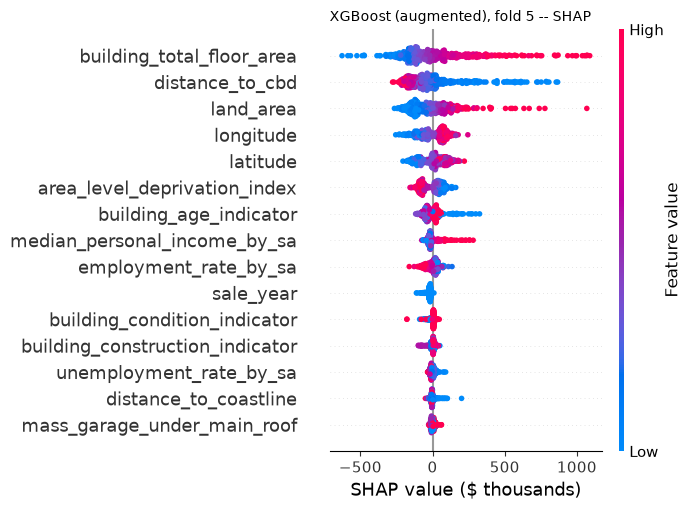

In [13]:
# In $ thousands so the axis has no "1e6" offset label.
shap.summary_plot(sv / 1000, shap_sample, max_display=15, show=False, plot_size=(7, 5.2))
plt.xlabel("SHAP value (\$ thousands)")
plt.title("XGBoost (augmented), fold 5 -- SHAP", fontsize=10, loc="left")
plt.tight_layout()
plt.savefig("figures/shap_xgboost_fold5.png", dpi=300, bbox_inches="tight")
plt.show()